In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils, base

In [32]:
# ns=200
# nd=300
# n = 10
# rng = jax.random.PRNGKey(12345)

beta= 5.75911 # non-int params3
b = 2.55
bk = 4.0

ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

# beta= 5.85277 # params3
# b = 2.55
# bk = 4.0

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_stepSize_record(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [33]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=1,
            bs=jnp.array([b])
        ) 

In [34]:
stepSizes_record = my_driver.steady_record.flatten()
stepSizes_record = stepSizes_record[jnp.nonzero(stepSizes_record)]

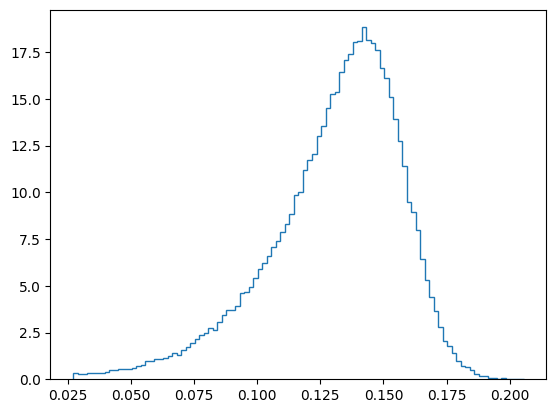

In [35]:
max_size = jnp.max(stepSizes_record)
min_size = jnp.min(stepSizes_record)
plt.hist(stepSizes_record, bins=100, density=True, histtype='step');

In [36]:
np.save("../data/fixed_params/stepSize_distribution/int_params3.npy", stepSizes_record)
# np.save("../tmp_data/int_params3.npy", wlens_array)

In [2]:
stepSizes_nonInt = np.load("../data/fixed_params/stepSize_distribution/nonInt_params3.npy")
stepSizes_int_variable_n_min1 = np.load("../data/fixed_params/stepSize_distribution/int_variableN_min1_params3.npy")
stepSizes_int = np.load("../data/fixed_params/stepSize_distribution/int_params3.npy")

np.mean(stepSizes_nonInt), np.mean(stepSizes_int_variable_n_min1), np.mean(stepSizes_int), np.var(stepSizes_nonInt), np.var(stepSizes_int_variable_n_min1), np.var(stepSizes_int)



(np.float32(0.12836094),
 np.float32(0.13010263),
 np.float32(0.13047907),
 np.float32(0.00059612415),
 np.float32(0.0018882316),
 np.float32(0.00068685535))

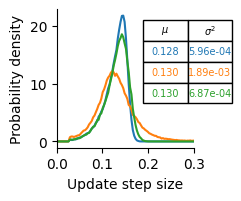

In [3]:
def hist_midpoints(data, bins, range_):
    counts, edges = np.histogram(data, bins=bins, range=range_, density=True)
    mids = 0.5 * (edges[:-1] + edges[1:])
    return mids, counts

fig, ax = plt.subplots(figsize=(2.3, 1.9), constrained_layout=True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

xmin = 0.
xmax = 0.3
bins = 100
range_ = (xmin, xmax)

for data, label in [
    (stepSizes_nonInt, "non-interacting"),
    (stepSizes_int_variable_n_min1, r'variable-$u_{\text{target}}$'),
    (stepSizes_int, "n-WTA"),
]:
    mids, counts = hist_midpoints(data, bins, range_)
    ax.plot(mids, counts, label=label)

# plt.hist(stepSizes_nonInt, bins=100, range=(xmin, xmax), density=True, histtype="step", label="non-interacting");
# plt.hist(stepSizes_int_variable_n_min1, bins=100, range=(xmin, xmax), density=True, histtype="step", label=r'variable-$u_{\text{target}}$');
# plt.hist(stepSizes_int, bins=100, range=(xmin, xmax), density=True, histtype="step", label="n-WTA");
ax.set_xlabel("Update step size");
ax.set_ylabel("Probability density");
ax.set_xlim(xmin, xmax)
# ax.legend(bbox_to_anchor=(0.6, 1), loc='upper left');

stats_data = [
    ('non-interacting', np.mean(stepSizes_nonInt), np.var(stepSizes_nonInt)),
    (r'variable-$u_{\text{target}}$', np.mean(stepSizes_int_variable_n_min1), np.var(stepSizes_int_variable_n_min1)),
    ('n-WTA', np.mean(stepSizes_int), np.var(stepSizes_int))
]
table_data = [[f'{mu:.3f}', f'{var:.2e}'] for _, mu, var in stats_data]

# Add table
table = ax.table(cellText=table_data,
                # rowLabels=row_labels,
                colLabels=[r'$\mu$', r'$\sigma^2$'],
                cellLoc='center',
                rowLoc='right',
                loc='upper right',
                bbox=[0.63, 0.32, 0.65, 0.6])

table.auto_set_font_size(False)
table.set_fontsize(7)

row_colors = ['C0', 'C1', 'C2']
for i, color in enumerate(row_colors, start=1):
    for j in range(2):
        table[(i, j)].get_text().set_color(color)


# plt.savefig("../figures/fig2/stepSize_distribution_params3.pdf", bbox_inches='tight')